# Amazon Reviews Sentiment Analysis: Multi-Layer Perceptron (MLP)
**Name / IT Number:** Waruna J.A.J. / `IT25102248`
**Model:** Multi-Layer Perceptron (feed-forward neural network, scikit-learn `MLPClassifier`)

This notebook uses the group's shared settings: the same 300,000-review random sample (seed 42), the same preprocessing, the same 80/20 stratified split, and 5-fold stratified cross-validation. Model varieties are compared with cross-validation on a development subset; the test set is used only once, for the final model.

In [1]:
%matplotlib inline
import os
import re
import random
from pathlib import Path
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report, confusion_matrix)


warnings.filterwarnings("ignore", category=ConvergenceWarning)   # max_iter is deliberately small
sns.set_theme(style="whitegrid")
STUDENT_ID = "IT25102248"

EPOCHS, BATCH_SIZE = 15, 32

# settings
SEED = 42
SAMPLE_SIZE = 300000
DATA_PATH = "../data/raw/train.ft.txt"
OUT_DIR = Path("../results/outputs")
FIG_DIR = Path("../results/eda_visualizations")
METRICS_DIR = Path("../results/final_metrics")
for folder in (OUT_DIR, FIG_DIR, METRICS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# stop here if the dataset is missing
assert os.path.exists(DATA_PATH), "train.ft.txt not found in data/raw/"

## 1. Load and preprocess the data
The same steps are used in all six notebooks, so every model is trained and tested on exactly the same reviews:
1. a random sample of 300,000 reviews from `train.ft.txt` (seed 42; the file is sorted, so the first rows would give a biased sample)
2. removing missing values and duplicate reviews
3. text cleaning (lowercase; remove HTML tags, links, numbers and punctuation)
4. removing outliers in review length with the IQR method
5. an 80/20 stratified train/test split (random_state = 42)

Labels: **0 = Negative, 1 = Positive**.

In [2]:
# load a random sample of the reviews
with open(DATA_PATH, "r", encoding="utf-8") as f:
    total_lines = sum(1 for _ in f)

random.seed(SEED)
keep = set(random.sample(range(total_lines), SAMPLE_SIZE))

labels, texts = [], []
with open(DATA_PATH, "r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i in keep:
            tag, _, text = line.strip().partition(" ")
            labels.append(1 if tag == "__label__2" else 0)   # 1 = positive, 0 = negative
            texts.append(text)
df = pd.DataFrame({"label": labels, "text": texts})

# missing values and duplicates
df["text"] = df["text"].replace("", np.nan)
df = df.dropna(subset=["text"]).drop_duplicates(subset="text").reset_index(drop=True)

# text cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)             # html tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # links
    text = re.sub(r"[^a-z\s]", " ", text)          # keep letters only
    return re.sub(r"\s+", " ", text).strip()

df["clean_text"] = df["text"].apply(clean_text)
df["word_count"] = df["clean_text"].str.split().str.len()

# outlier removal on review length (IQR method)
q1, q3 = df["word_count"].quantile([0.25, 0.75])
iqr = q3 - q1
df = df[(df["word_count"] >= q1 - 1.5 * iqr) &
        (df["word_count"] <= q3 + 1.5 * iqr)].reset_index(drop=True)

# 80/20 stratified train/test split
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# 5-fold stratified cross-validation and a smaller subset of the training data for tuning
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def dev_subset(data, n=100000):
    subset, _ = train_test_split(data, train_size=n, stratify=data["label"], random_state=SEED)
    return subset.reset_index(drop=True)

print(f"full file: {total_lines:,} reviews | after preprocessing: {len(df):,}")
print(f"train: {len(train_df):,} | test: {len(test_df):,}")
print("positive share (train / test):", round(train_df["label"].mean(), 4), round(test_df["label"].mean(), 4))

full file: 3,600,000 reviews | after preprocessing: 299,983
train: 239,986 | test: 59,997
positive share (train / test): 0.5002 0.5002


In [3]:
dev = dev_subset(train_df, 50_000)
y_train, y_test, y_dev = train_df["label"], test_df["label"], dev["label"]
print("train:", len(train_df), "| test:", len(test_df), "| dev subset:", len(dev))

train: 239986 | test: 59997 | dev subset: 50000


## 2. Preprocessing variants (baseline MLP)

The baseline network from the earlier version is kept fixed — 2 hidden layers (16, 8), ReLU, Adam, batch size 32, 15 epochs — while the text features change:

| Variant | TF-IDF features | Stop words | N-grams |
|---|---|---|---|
| V1 (original baseline) | 1,000 | removed | unigrams |
| V2 | 1,000 | kept | unigrams |
| V3 | 10,000 | kept | unigrams |
| V4 | 10,000 | kept | unigrams + bigrams |

In [4]:
def mlp(**kw):
    params = dict(hidden_layer_sizes=(16, 8), activation="relu", solver="adam",
                  batch_size=BATCH_SIZE, max_iter=EPOCHS, random_state=SEED)
    params.update(kw)
    return MLPClassifier(**params)

feature_variants = {
    "V1: 1k, stop words removed (original)": dict(max_features=1000, stop_words="english"),
    "V2: 1k, stop words kept": dict(max_features=1000),
    "V3: 10k, stop words kept": dict(max_features=10000),
    "V4: 10k, stop words kept, bigrams": dict(max_features=10000, ngram_range=(1, 2)),
}

variant_rows = []
for name, tf_kw in feature_variants.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(**tf_kw)), ("mlp", mlp())])
    start = time.time()
    s = cross_validate(pipe, dev["clean_text"], y_dev, cv=CV, scoring=["accuracy", "f1"],
                       return_train_score=True, n_jobs=-1)
    variant_rows.append({"variant": name,
                         "train_f1": round(float(s["train_f1"].mean()), 4),
                         "cv_accuracy": round(float(s["test_accuracy"].mean()), 4),
                         "cv_f1": round(float(s["test_f1"].mean()), 4),
                         "cv_std": round(float(s["test_f1"].std()), 4),
                         "time_s": round(time.time() - start, 1)})
    print(f"{name}: CV F1 = {variant_rows[-1]['cv_f1']}  ({variant_rows[-1]['time_s']} s)")

variants_df = pd.DataFrame(variant_rows)
best_variant = variants_df.loc[variants_df["cv_f1"].idxmax(), "variant"]
best_tfidf = feature_variants[best_variant]
print("\nBest feature set:", best_variant)
variants_df

V1: 1k, stop words removed (original): CV F1 = 0.8424  (16.7 s)
V2: 1k, stop words kept: CV F1 = 0.8619  (17.9 s)
V3: 10k, stop words kept: CV F1 = 0.8522  (175.4 s)
V4: 10k, stop words kept, bigrams: CV F1 = 0.8754  (153.4 s)

Best feature set: V4: 10k, stop words kept, bigrams


,variant,train_f1,cv_accuracy,cv_f1,cv_std,time_s
0,"V1: 1k, stop words removed (original)",0.9069,0.8428,0.8424,0.0041,16.7
1,"V2: 1k, stop words kept",0.9164,0.8624,0.8619,0.0035,17.9
2,"V3: 10k, stop words kept",0.9972,0.8526,0.8522,0.0021,175.4
3,"V4: 10k, stop words kept, bigrams",0.9974,0.8751,0.8754,0.0022,153.4


**Observations (section 2)**

- The original baseline (1,000 features, stop words removed) gives a CV F1 of 0.8424.
- Keeping stop words raised it to 0.8619 (+1.95 points).
- Using 10,000 unigram features lowered it to 0.8522, even though the train F1 rose to 0.9972. The (16, 8) network without regularisation memorises the training folds in 15 epochs, so it over-fits.
- Adding bigrams (V4) gave the best result, 0.8754 (+3.30 points over the baseline), so V4 is used for tuning.

## 3. Hyperparameter tuning (overfitting mitigation)

GridSearchCV tunes the architecture and the L2 penalty `alpha` on the best feature set, with **early stopping** (10 % validation split, patience 5, up to 30 epochs). 9 combinations × 5 folds = 45 fits, scored by F1.

In [5]:
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(**best_tfidf)),
    ("mlp", mlp(early_stopping=True, validation_fraction=0.1, n_iter_no_change=5, max_iter=30)),
])
param_grid = {
    "mlp__hidden_layer_sizes": [(16, 8), (32, 16), (64, 32)],
    "mlp__alpha": [1e-4, 1e-3, 1e-2],
}
grid = GridSearchCV(pipe, param_grid, cv=CV, scoring="f1", n_jobs=-1,
                    verbose=1, return_train_score=True)
start = time.time()
grid.fit(dev["clean_text"], y_dev)
print(f"time: {(time.time() - start) / 60:.1f} min")
print("best params:", grid.best_params_)
print(f"best CV F1: {grid.best_score_:.4f}")

cv_table = pd.DataFrame(grid.cv_results_)[[
    "param_mlp__hidden_layer_sizes", "param_mlp__alpha",
    "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"
]].sort_values("rank_test_score")
cv_table.round(4)

Fitting 5 folds for each of 9 candidates, totalling 45 fits
time: 34.4 min
best params: {'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (16, 8)}
best CV F1: 0.9029


,param_mlp__hidden_layer_sizes,param_mlp__alpha,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,"(16, 8)",0.0001,0.9424,0.9029,0.0017,1
3,"(16, 8)",0.0010,0.9421,0.9025,0.0015,2
6,"(16, 8)",0.0100,0.9373,0.9014,0.0025,3
2,"(64, 32)",0.0001,0.9470,0.9008,0.0017,4
5,"(64, 32)",0.0010,0.9463,0.9005,0.0016,5
4,"(32, 16)",0.0010,0.9435,0.9004,0.0045,6
1,"(32, 16)",0.0001,0.9465,0.9000,0.0043,7
7,"(32, 16)",0.0100,0.9382,0.8976,0.0050,8
8,"(64, 32)",0.0100,0.9380,0.8970,0.0017,9


**Observations (section 3)**

- Early stopping and L2 regularisation raised the CV F1 from 0.8754 to 0.9029 (+2.75 points), mainly because early stopping ends training before the network over-fits.
- The smallest network (16, 8) with alpha = 0.0001 was the best. The larger networks (32, 16) and (64, 32) were not better (best 0.9008), so extra capacity does not help here.
- alpha = 0.01 gave the lowest score for every network size (0.8970 to 0.9014), so too much regularisation under-fits slightly.
- The grid search took 34.4 minutes, which makes the MLP the slowest model to tune.

## 4. Final model and test evaluation
The tuned network is trained on the full training set (239,986 reviews). The test set is used only here, once.

In [ ]:
final_model = clone(grid.best_estimator_)
#Training time measuring
start = time.time()
final_model.fit(train_df["clean_text"], y_train)
mlp_train_time = round(time.time() - start, 1)
net = final_model.named_steps["mlp"]
print(f"training time: {mlp_train_time} s | epochs run: {net.n_iter_}")

y_pred = final_model.predict(test_df["clean_text"])
y_prob = final_model.predict_proba(test_df["clean_text"])[:, 1]
#Accuracy And Precision
acc, prec = accuracy_score(y_test, y_pred), precision_score(y_test, y_pred)
#Recall And F1
rec, f1 = recall_score(y_test, y_pred), f1_score(y_test, y_pred)
#ROC-AUC
auc = roc_auc_score(y_test, y_prob)
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC AUC  : {auc:.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], digits=4))
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

training time: 301.9 s | epochs run: 9
Accuracy : 0.9170
Precision: 0.9135
Recall   : 0.9213
F1 Score : 0.9174
ROC AUC  : 0.9740

              precision    recall  f1-score   support

    Negative     0.9205    0.9127    0.9166     29986
    Positive     0.9135    0.9213    0.9174     30011

    accuracy                         0.9170     59997
   macro avg     0.9170    0.9170    0.9170     59997
weighted avg     0.9170    0.9170    0.9170     59997

Confusion matrix:
 [[27369  2617]
 [ 2363 27648]]


## 5. Training curves, confusion matrix and ROC
The baseline network (V1 settings, no regularisation) is also trained on the full training set only to compare its loss curve with the tuned model; it is not evaluated on the test set.

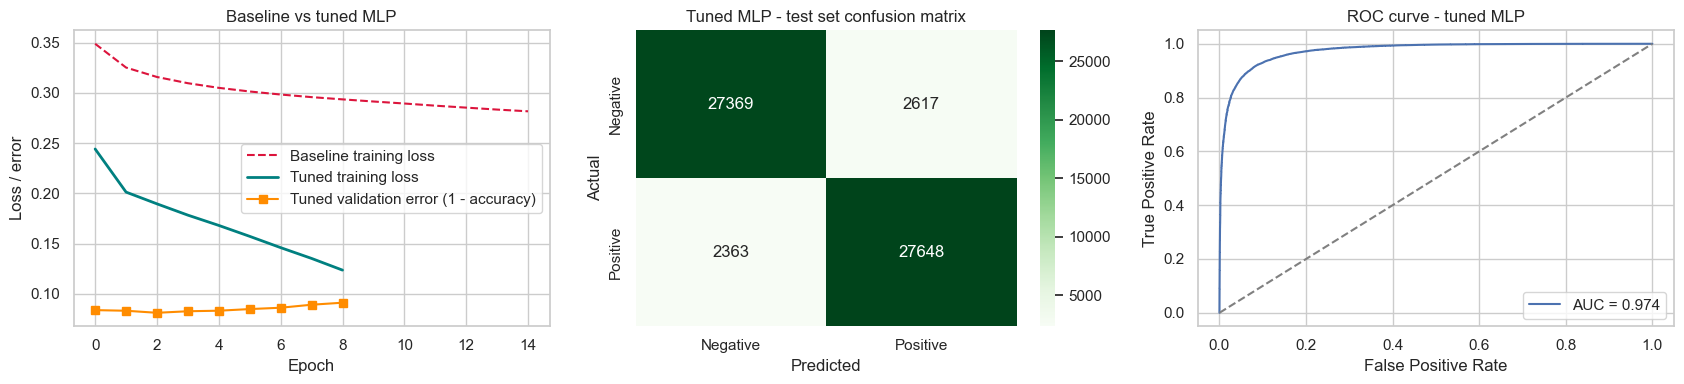

Total errors: 4980 of 59997

Error rate by review length:
                 mean   sum  count
length_bucket                     
short          0.0745  1502  20171
medium         0.0800  1604  20048
long           0.0948  1874  19778


In [ ]:
#Create Baseline model
baseline = Pipeline([("tfidf", TfidfVectorizer(**feature_variants["V1: 1k, stop words removed (original)"])),
                     ("mlp", mlp())])
baseline.fit(train_df["clean_text"], y_train)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
#Baseline training loss
axes[0].plot(baseline.named_steps["mlp"].loss_curve_, "--", color="crimson", label="Baseline training loss")
#Tuned model training loss
axes[0].plot(net.loss_curve_, color="teal", lw=2, label="Tuned training loss")
#Tuned validation error
if getattr(net, "validation_scores_", None) is not None:
    axes[0].plot(1 - np.array(net.validation_scores_), color="darkorange", marker="s",
                 label="Tuned validation error (1 - accuracy)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss / error")
axes[0].set_title("Baseline vs tuned MLP"); axes[0].legend()

#Confusion Matrix
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
axes[1].set_title("Tuned MLP - test set confusion matrix")

#ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[2].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
axes[2].plot([0, 1], [0, 1], "--", color="grey")
axes[2].set_xlabel("False Positive Rate"); axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("ROC curve - tuned MLP"); axes[2].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "mlp_curves_cm_roc.png", dpi=150, bbox_inches="tight")
plt.show()

#Error Analysis
err = pd.DataFrame({"true": y_test.values, "pred": y_pred, "word_count": test_df["word_count"].values})
#Identify Wrong predictions
err["wrong"] = err["true"] != err["pred"]
err["length_bucket"] = pd.qcut(err["word_count"], q=3, labels=["short", "medium", "long"])
print("Total errors:", err["wrong"].sum(), "of", len(err))
print("\nError rate by review length:")
#Error rate by review length
print(err.groupby("length_bucket", observed=True)["wrong"].agg(["mean", "sum", "count"]).round(4))

**Observations (sections 4-5)**

- Early stopping ended training after 9 epochs (301.9 s on the full training set).
- On the test set the final model reaches accuracy 0.9170, precision 0.9135, recall 0.9213, F1 0.9174 and ROC-AUC 0.9740.
- There are 4,980 errors (8.30 %): 2,617 negative reviews predicted as positive and 2,363 positive reviews predicted as negative, so precision (0.9135) is a little lower than recall (0.9213).
- The test F1 is 1.45 points above the CV F1 (0.9029), because the final model used all 239,986 training reviews.
- The error rate increases with review length: 7.45 % short, 8.00 % medium and 9.48 % long.
- In the live test (section 7), "Not bad for the price" is predicted as positive (88.9 %), because the bigram "not bad" is one of the features.

## 6. Summary of results and saving

In [8]:
rows = [{"model_variant": r["variant"] + ", MLP (16, 8)", "validation": "5-fold CV (50k dev subset)",
         "accuracy": r["cv_accuracy"], "f1": r["cv_f1"], "roc_auc": None}
        for _, r in variants_df.iterrows()]
rows.append({"model_variant": f"Tuned (GridSearchCV): {grid.best_params_}",
             "validation": "5-fold CV (50k dev subset)",
             "accuracy": None, "f1": round(grid.best_score_, 4), "roc_auc": None})
rows.append({"model_variant": "FINAL: tuned MLP on full training set",
             "validation": f"Held-out test set ({len(test_df):,} reviews)",
             "accuracy": round(acc, 4), "f1": round(f1, 4), "roc_auc": round(auc, 4)})
summary = pd.DataFrame(rows)
summary.to_csv(OUT_DIR / "mlp_model_summary.csv", index=False)
cv_table.to_csv(OUT_DIR / "mlp_gridsearch_results.csv", index=False)
joblib.dump(final_model, OUT_DIR / "mlp_final_model.joblib")
print("Saved:", OUT_DIR / "mlp_model_summary.csv")

# save the final result for the group comparison (same format in all six notebooks)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
result = {
    "model": "MLP Neural Network", "student_id": STUDENT_ID,
    "accuracy": round(accuracy_score(y_test, y_pred), 4),
    "precision": round(precision_score(y_test, y_pred), 4),
    "recall": round(recall_score(y_test, y_pred), 4),
    "f1": round(f1_score(y_test, y_pred), 4),
    "f1_macro": round(f1_score(y_test, y_pred, average="macro"), 4),
    "roc_auc": round(roc_auc_score(y_test, y_prob), 4),
    "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    "cv_f1_mean": round(grid.best_score_, 4),
    "cv_f1_std": round(grid.cv_results_["std_test_score"][grid.best_index_], 4),
    "train_time_s": mlp_train_time, "n_train": len(train_df),
    "best_params": str({**grid.best_params_, "tfidf": best_variant}), "notes": "Tuned on 50k dev subset with 5-fold CV; early stopping",
}
pd.DataFrame([result]).to_csv(os.path.join(METRICS_DIR, "MLP_Neural_Network.csv"), index=False)
print("Saved:", os.path.join(METRICS_DIR, "MLP_Neural_Network.csv"))

pd.set_option("display.max_colwidth", 90)
summary

Saved: ..\results\outputs\mlp_model_summary.csv
Saved: ..\results\final_metrics\MLP_Neural_Network.csv


,model_variant,validation,accuracy,f1,roc_auc
0,"V1: 1k, stop words removed (original), MLP (16, 8)",5-fold CV (50k dev subset),0.8428,0.8424,NaN
1,"V2: 1k, stop words kept, MLP (16, 8)",5-fold CV (50k dev subset),0.8624,0.8619,NaN
2,"V3: 10k, stop words kept, MLP (16, 8)",5-fold CV (50k dev subset),0.8526,0.8522,NaN
3,"V4: 10k, stop words kept, bigrams, MLP (16, 8)",5-fold CV (50k dev subset),0.8751,0.8754,NaN
4,"Tuned (GridSearchCV): {'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (16, 8)}",5-fold CV (50k dev subset),NaN,0.9029,NaN
5,FINAL: tuned MLP on full training set,"Held-out test set (59,997 reviews)",0.9170,0.9174,0.974


## 7. Live custom review predictor

In [9]:
def predict_review(review_text, model=final_model):
    prob = model.predict_proba([clean_text(review_text)])[0]
    pred = int(prob[1] >= 0.5)
    sentiment = "Good Review (Positive)" if pred == 1 else "Bad Review (Negative)"
    print(f"Review     : \"{review_text}\"")
    print(f"Prediction : {sentiment}")
    print(f"Confidence : {prob[pred] * 100:.2f}%  [Bad: {prob[0]*100:.1f}%, Good: {prob[1]*100:.1f}%]\n")

for comment in ["This product is absolutely amazing! Excellent quality and super fast delivery.",
                "Terrible item, arrived broken and does not work at all. Total waste of money!",
                "Not bad for the price, works decently.",
                "Very disappointed with the battery life. Died within 2 days."]:
    predict_review(comment)

Review     : "This product is absolutely amazing! Excellent quality and super fast delivery."
Prediction : Good Review (Positive)
Confidence : 99.89%  [Bad: 0.1%, Good: 99.9%]

Review     : "Terrible item, arrived broken and does not work at all. Total waste of money!"
Prediction : Bad Review (Negative)
Confidence : 99.98%  [Bad: 100.0%, Good: 0.0%]

Review     : "Not bad for the price, works decently."
Prediction : Good Review (Positive)
Confidence : 88.86%  [Bad: 11.1%, Good: 88.9%]

Review     : "Very disappointed with the battery life. Died within 2 days."
Prediction : Bad Review (Negative)
Confidence : 99.59%  [Bad: 99.6%, Good: 0.4%]



## 8. Conclusion

An MLP with TF-IDF features was trained on the shared sample (239,986 training and 59,997 test reviews).

- Keeping stop words and adding bigrams raised the CV F1 from 0.8424 (baseline) to 0.8754, and early stopping with L2 tuning raised it to 0.9029.
- On the test set the tuned network scored accuracy 0.9170, F1 0.9174 and ROC-AUC 0.9740, the third-best result in the group after the Linear SVM and Logistic Regression.

**Limitations:** the MLP was the slowest model to tune (34 minutes), its result depends on the random weight initialisation, and it is harder to explain than a linear model. Bag-of-words features cannot capture word order.